<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Standard_Problem_5_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

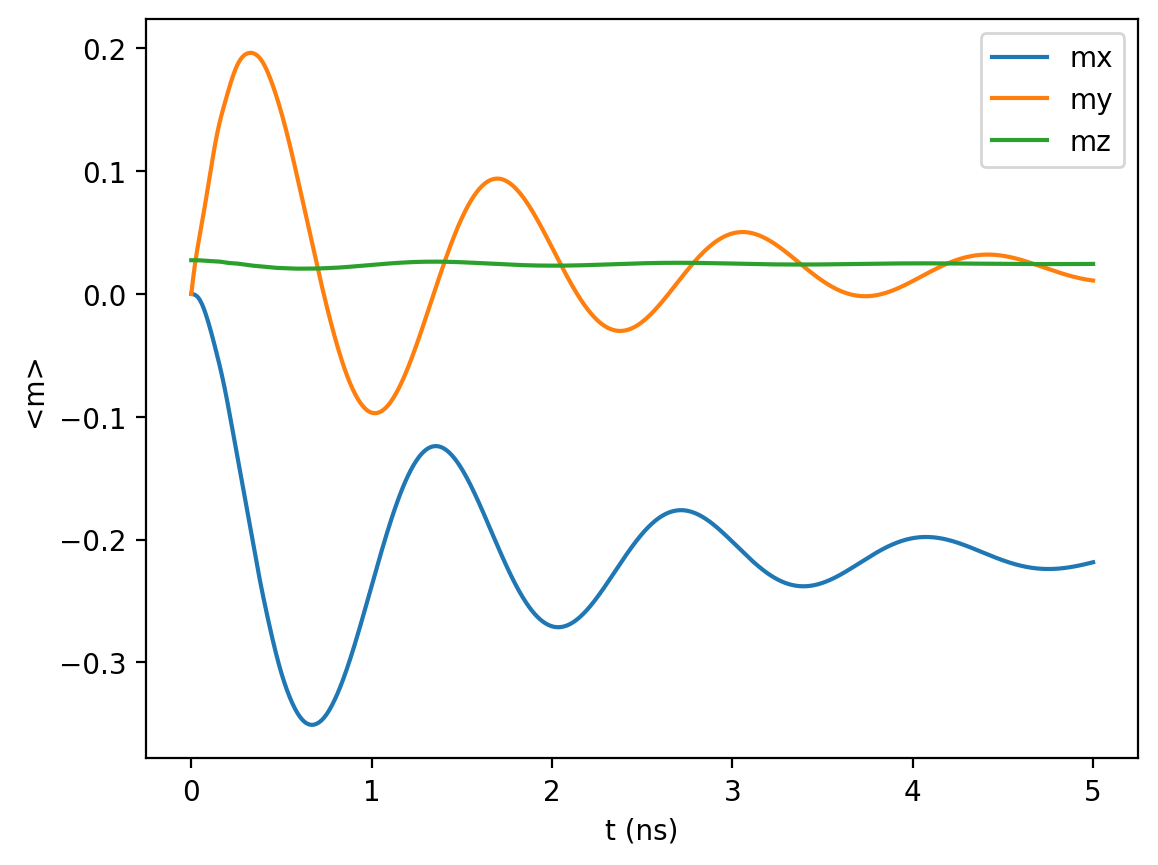

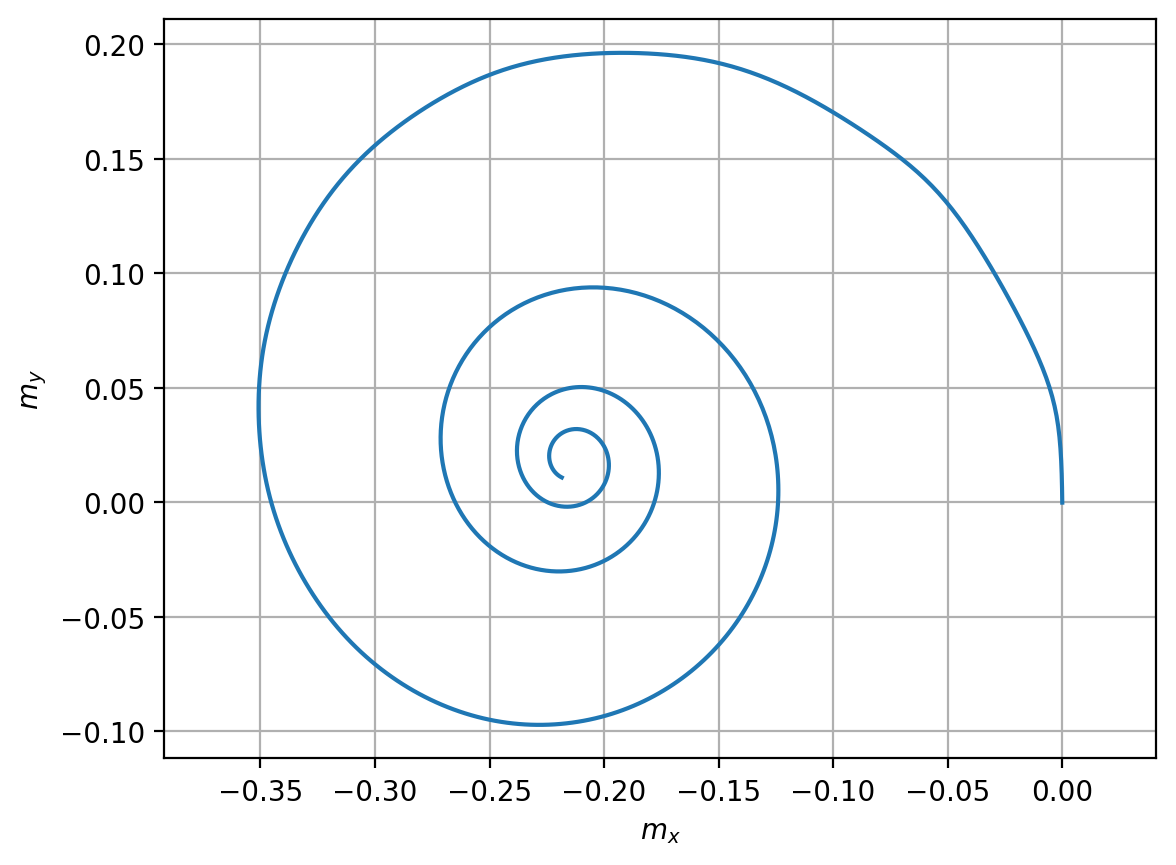

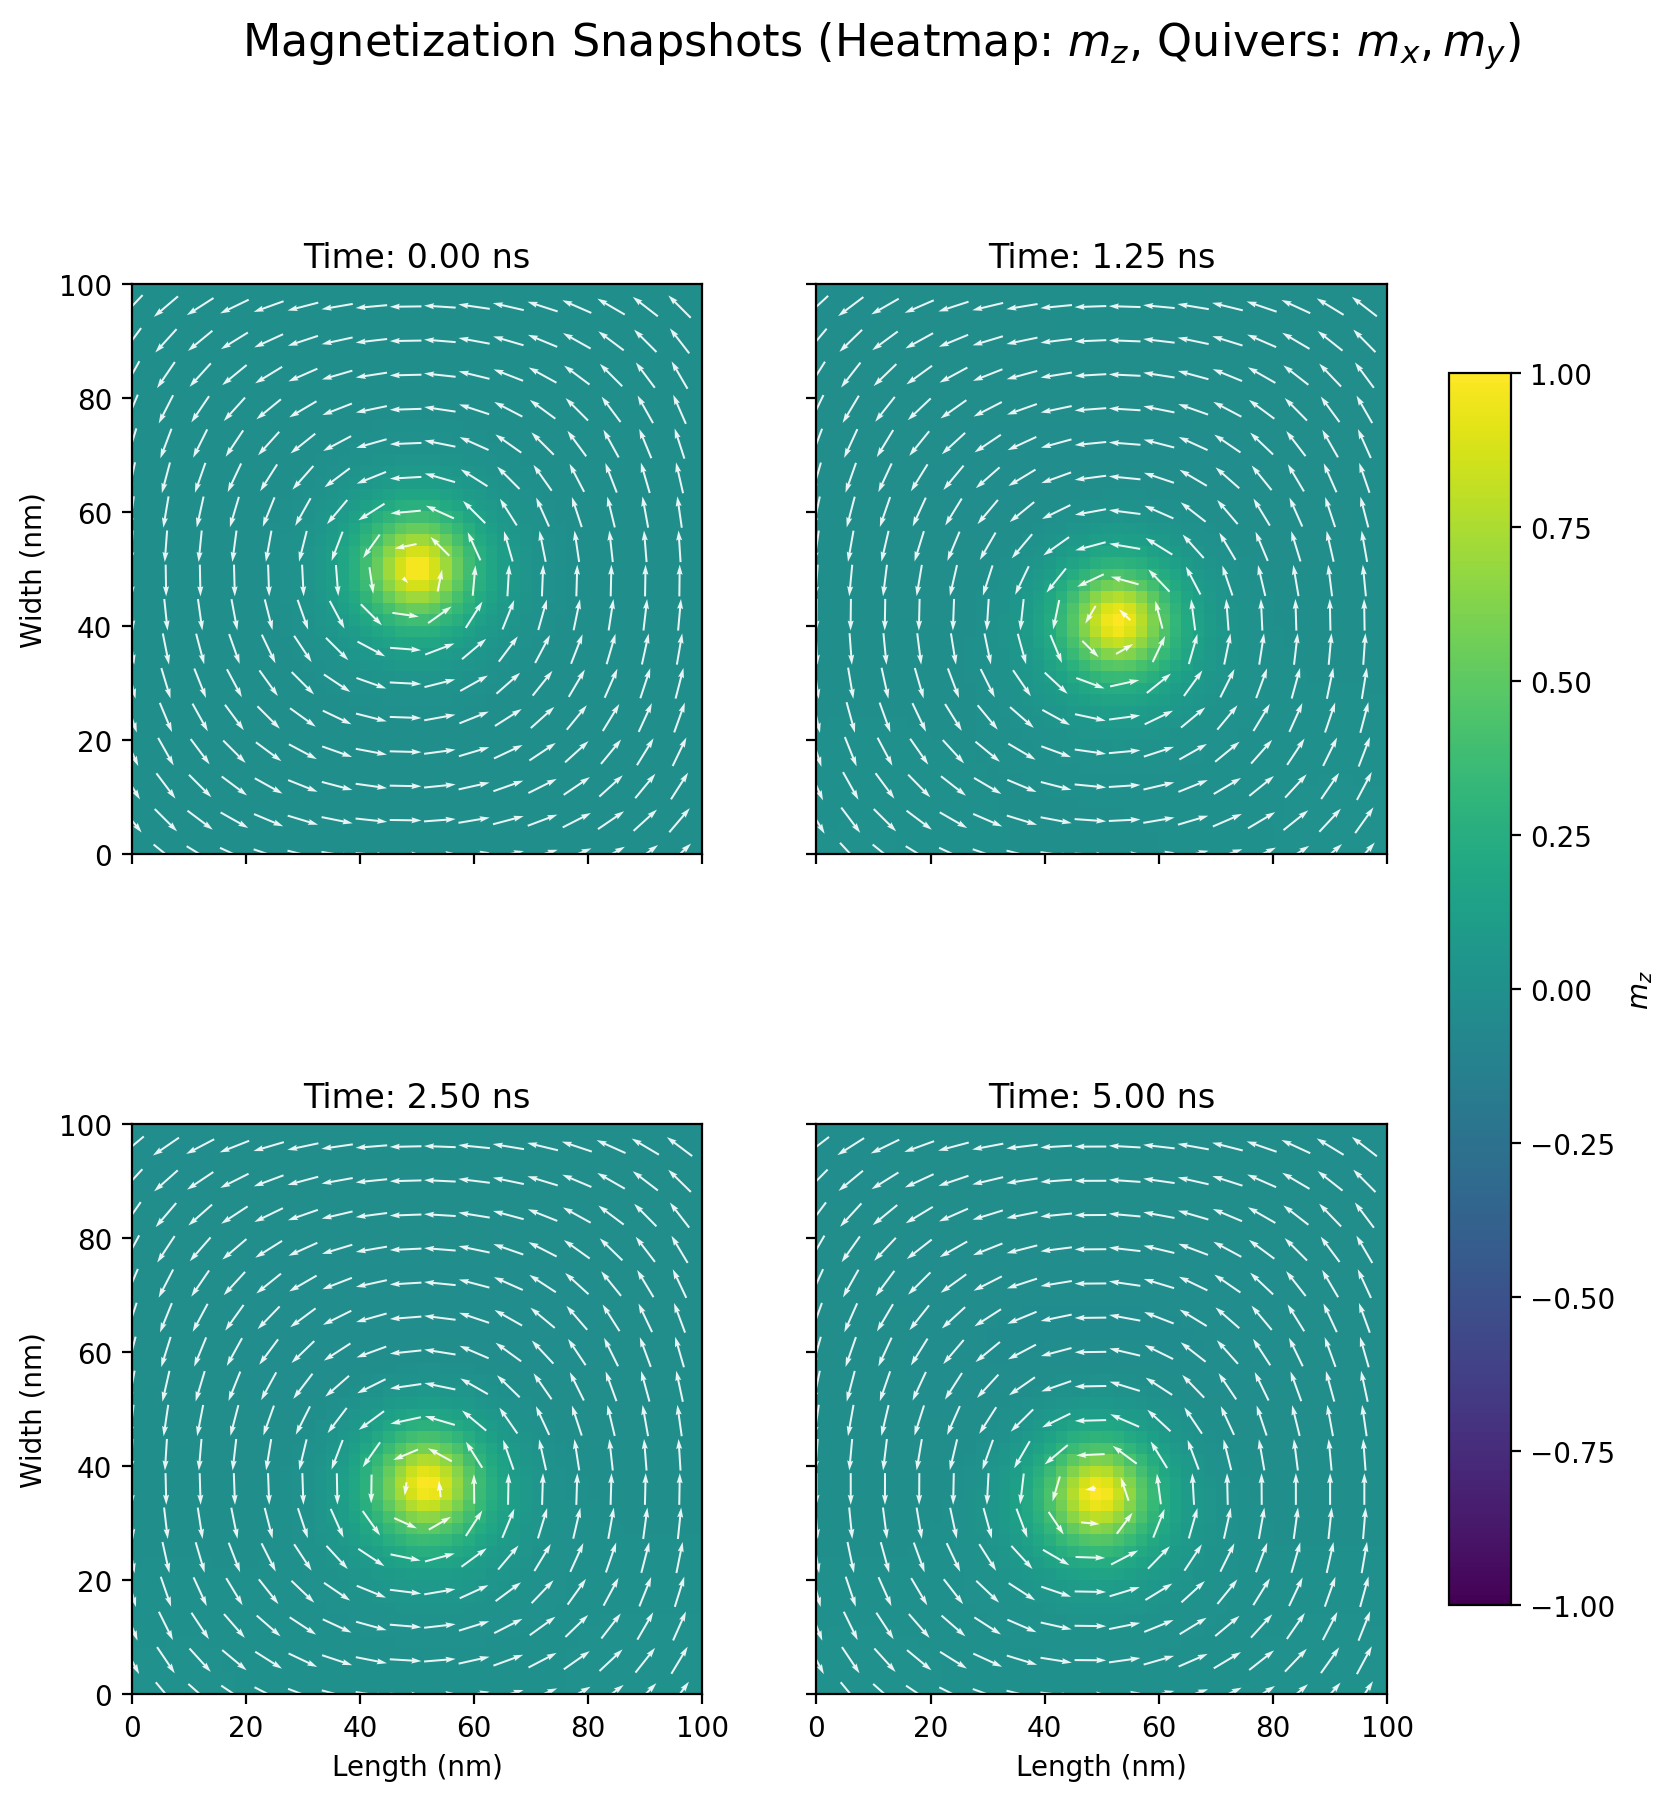

In [23]:
# This script solves micromagnetic standard problem 5. The Problem specification
# can be found on https://www.ctcms.nist.gov/~rdm/mumag.org.html

# Import libraries
import matplotlib.pyplot as plt
from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World
import numpy as np

plt.rcParams["figure.dpi"] = 200

# Define initial configuration function
def get_initial_config(position, radius):
    x0, y0, _ = position

    def func(x, y, z):
        x -= x0
        y -= y0
        return (-y, x, radius)

    return func

# Specify simulation world
length, width, thickness = 100e-9, 100e-9, 10e-9
nx, ny, nz = 50, 50, 5
world = World(cellsize=(length / nx, width / ny, thickness / nz))

# Initialize ferromagnet parameters
magnet = Ferromagnet(world, Grid((nx, ny, nz)))
magnet.msat = 800e3
magnet.aex = 13e-12
magnet.alpha = 0.1

# Relax initial magnetization
radius = 10e-9
magnet.magnetization = get_initial_config(
    (length / 2, width / 2, thickness / 2), radius
)
magnet.minimize()

# Apply spin-polarized current
xi1, xi2, xi3, xi4 = 0.0, 0.05, 0.1, 0.5
magnet.xi = xi2
magnet.pol = 1.0
magnet.jcur = (1e12, 0, 0)

# Schedule solver output
timepoints = np.linspace(0, 5e-9, 1000)
outputquantities = {
    "mx": lambda: magnet.magnetization.average()[0],
    "my": lambda: magnet.magnetization.average()[1],
    "mz": lambda: magnet.magnetization.average()[2],
    "m_field": lambda: magnet.magnetization.eval(),
}

# Run time solver
output = world.timesolver.solve(timepoints, outputquantities)

# Plot magnetization time series and phase portrait
t_fig, t_ax = plt.subplots()
for key in ["mx", "my", "mz"]:
    t_ax.plot(np.asarray(output["time"]) * 1e9, output[key], label=key)
t_ax.legend()
t_ax.set_xlabel("t (ns)")
t_ax.set_ylabel("<m>")

mm_fig, mm_ax = plt.subplots()
mm_ax.axis("equal")
mm_ax.plot(output["mx"], output["my"])
mm_ax.set_xlabel("$m_x$")
mm_ax.set_ylabel("$m_y$")
mm_ax.grid()

plt.show()

# Plot spatial magnetization snapshots
snapshot_indices = [0, 250, 500, 999]
fig, axes = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)
axes = axes.flatten()
extent = [0, length * 1e9, 0, width * 1e9]

# Extract spatial coordinates in nm directly from mumaxplus meshgrid
x_mesh, y_mesh, _ = magnet.magnetization.meshgrid
skip = 3
x_grid = x_mesh[nz // 2, ::skip, ::skip] * 1e9
y_grid = y_mesh[nz // 2, ::skip, ::skip] * 1e9

for i, idx in enumerate(snapshot_indices):
    ax = axes[i]

    # Note: magnet.magnetization.eval() returns an array of shape (3, nz, ny, nx)
    m_data = output["m_field"][idx]
    mx, my, mz = m_data[0], m_data[1], m_data[2]

    # Average across thickness (axis=0 corresponds to nz)
    mz_slice = np.mean(mz, axis=0)
    im = ax.imshow(
        mz_slice,
        extent=extent,
        cmap="viridis",
        origin="lower",
        vmin=-1.0,
        vmax=1.0,
    )

    # Extract middle thickness slice (nz // 2) along axis 0 for quiver arrows
    u_comp = mx[nz // 2, ::skip, ::skip]
    v_comp = my[nz // 2, ::skip, ::skip]

    ax.quiver(
        x_grid,
        y_grid,
        u_comp,
        v_comp,
        color="white",
        pivot="mid",
        angles="xy",
        scale_units="xy",
        scale=0.18,
        alpha=0.9,
    )
    ax.set_title(f"Time: {timepoints[idx] * 1e9:.2f} ns")

    if i in (0, 2):
        ax.set_ylabel("Width (nm)")
    if i in (2, 3):
        ax.set_xlabel("Length (nm)")

fig.colorbar(im, ax=axes.tolist(), label="$m_z$", shrink=0.8, pad=0.04)
plt.suptitle(
    "Magnetization Snapshots (Heatmap: $m_z$, Quivers: $m_x, m_y$)",
    fontsize=16,
)
plt.show()